In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [56]:
# Load the dataset
df = pd.read_csv(r'C:\Users\suyas\OneDrive\Documents\Desktop\Customer Churn  prediction\data\raw\Telco-Customer-Churn.csv')

In [57]:
# Basic Data Exploration
print(df.shape)
print(df.columns)
print(df.head())

(7043, 21)
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No 

In [58]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [59]:
# EDA Process
# Step 1 - churn distribution
# check churn distribution
print(df['Churn'].value_counts())


Churn
No     5174
Yes    1869
Name: count, dtype: int64


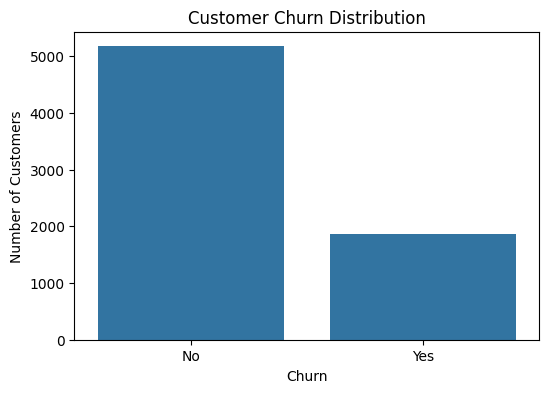

In [60]:
# plot churn distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

Insight:
The dataset shows class imbalance, with significantly more non-churn customers than churn customers. This imabalance need to be handled during model evaluation.

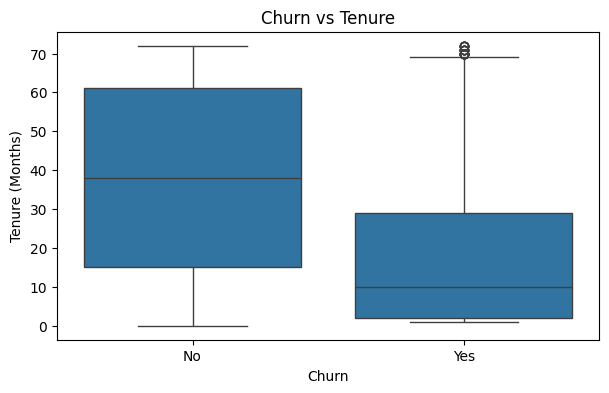

In [61]:
# Step 2 - Churn vs Tenure
# we want to ans : Do customers who stay for a shorter time churn more?

plt.figure(figsize=(7,4))
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title("Churn vs Tenure")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

Insight :
Customer with lower tenure have a significantly higher churn rate, indicating that early customer engagement is critical for retention.

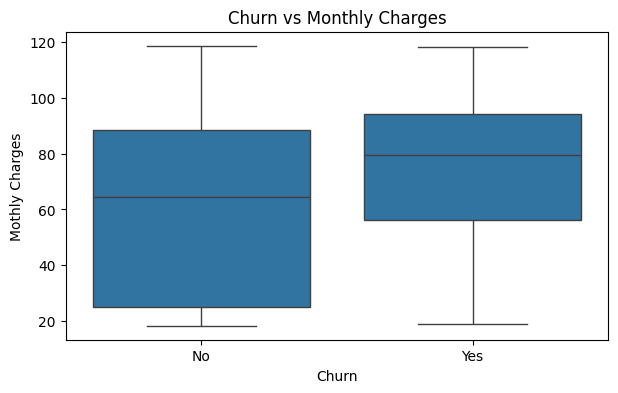

In [62]:
# Step 3 - Churn vs Monthly Charges
# We want to know : Do customers with higher monthly bills leave more often

plt.figure(figsize=(7,4))
sns.boxplot(x='Churn', y='MonthlyCharges',data=df)
plt.title("Churn vs Monthly Charges")
plt.xlabel("Churn")
plt.ylabel("Mothly Charges")
plt.show()

Insight: 
Customer with highly monthly charges show a higher tendency to churn, suggesting that pricing and perceived value play a significant role in customer retention.

In [63]:
# Step 4 - Churn vs Contract Type
# We want to know : Does contract duration affect churn?

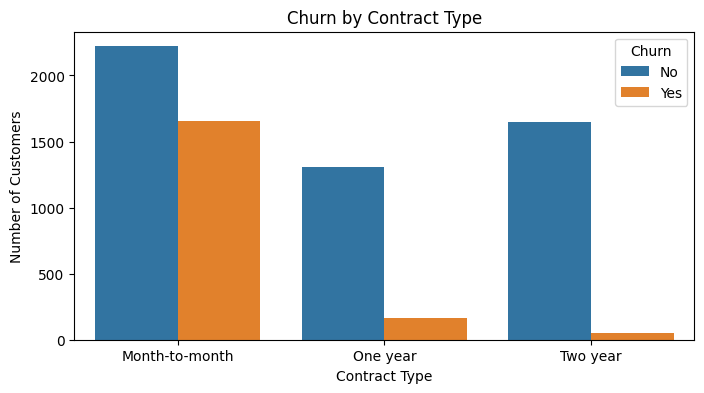

In [64]:
plt.figure(figsize=(8,4))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

Insight:
Customer on month-to-month contracts exhibit significantly higher churn, while long-term contracts show better customer retention.

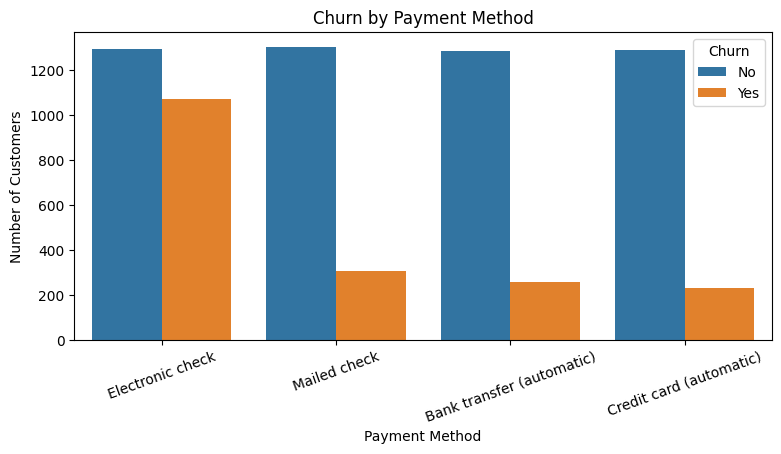

In [65]:
# Step 5 - Churn vs Payment Method
# Does the way customers pay affect churn?

plt.figure(figsize=(9,4))
sns.countplot(x='PaymentMethod', hue='Churn', data=df)
plt.title("Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.show()

Insight:
Customers using electronic checks show higher churn, while automated payment methods are associated with better retention, suggesting payment convenience reduces churn.

In [66]:
# Phase 3 
# Step 1 : Fix data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [67]:
# we can see that TotalCharges column datatype is object but it should be numeric
# Convert total charges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [68]:
# Step 2 - Handle Missing Values
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [69]:
# TotalCharges have 11 missing values
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

C:\Users\suyas\AppData\Local\Temp/ipykernel_27776/2007656482.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


Converted TotalCharges to numeric format and handled missing values using median imputation to ensure compatibility with machine learning models.

In [70]:
# Step 3A - Drop Useless Columns
# drop customerID (not useful for prediction)
df.drop(columns=['customerID'], inplace=True)

Feature Selection:
Removed customerID as it does not contribute to churn prediction and only serves as a unique identifier.

In [71]:
# Step 3B - Separate Target Variable
# target variable
y = df['Churn']

# Features
X = df.drop(columns=['Churn'])

# Check shapes:
X.shape, y.shape


((7043, 19), (7043,))

In [72]:
# Step 4 - Encoding (Covert Text to Numbers)

# Step 4A - Encode Target Variale
# encode target variable
y = y.map({'Yes': 1, 'No': 0})

# Step 4B - Find Categorical Columns
# identify categorical columns
# In simple words We are finding columns that contain text, not numbers.
categorical_cols = X.select_dtypes(include='object').columns
categorical_cols

# Step 4C - One-Hot Encode Categorical Features
# one-hot encode categorical variables
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# get_dummies() → convert text into 0/1 columns
# columns=categorical_cols → apply only to text columns
# drop_first=True → remove one extra column to avoid confusion

Feature Engineering:
Encoded categorical variables using one-hot encoding and converted the target variable into binary format to make the dataset suitable for machine learning models.

In [73]:
# Train Test Split
from sklearn.model_selection import  train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [74]:
# Step 5 - Feature  Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

#  fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# transform test data
X_test_scaled = scaler.transform(X_test)

Feature Scaling:
Applied standardization to numerical features using StandardScaler after train-test split to ensure fair feature contribution and prevent data leakage.

In [75]:
# Phase 4 : Model Building(Logistic Regression)
''' STEP 1: Why Logistic Regression?
    Output is probability (0-1)
    Perfect for Yes / No problems
'''
# Step 2 - Train Logistic Regression
from sklearn.linear_model import LogisticRegression

# create model
log_reg = LogisticRegression(max_iter=1000)

#train model
log_reg.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [76]:
# Step 3 - Make Predictions (predict on test data)
y_pred =  log_reg.predict(X_test_scaled)
#  0 -> will  stay
#  1 -> will churn


In [77]:
#Step 4 - Evaluate the Model
# Confusion Matrix

from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)
print(cm)

# TP → correctly predicted churn

# FN → missed churn (very costly in business)

[[925 110]
 [162 212]]


In [78]:
# Classification Report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [79]:
# step 5 - ROC-AUC Score

from sklearn.metrics import roc_auc_score
y_prob = log_reg.predict_proba(X_test_scaled)[:, 1]
roc_auc = roc_auc_score(y_test,y_prob)

print("ROC-AUC Score:", roc_auc)


ROC-AUC Score: 0.841649228861505


Modeling:
Trained a Logistic Regression model as a baseline classifier and evaluated performance using confusion matrix, classification report, and ROC-AUC score due to class imbalance.

In [80]:
# Phase 5 - Random Forest
# Step 1 - Train Random Forest Model

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'  # important for churn
)

rf.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [81]:
# Step 2 - Make Predictions

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

In [82]:
# Step 3 - Evalute Random Forest

from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

[[926 109]
 [188 186]]
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [83]:
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.8245705133173165


In [84]:
# Phase 5 - Model Improvement
# STEP 1: Apply SMOTE on Training Data

from imblearn.over_sampling import SMOTE

# initialize SMOTE
smote = SMOTE(random_state=42)

# apply SMOTE only on training data
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# check new distribution
pd.Series(y_train_smote).value_counts()


Churn
0    4139
1    4139
Name: count, dtype: int64

In [85]:
# STEP 2: Train Logistic Regression Again
# train logistic regression on SMOTE data
log_reg_smote = LogisticRegression(max_iter=1000)

log_reg_smote.fit(X_train_smote, y_train_smote)


LogisticRegression(max_iter=1000)

In [86]:
# STEP 3 - Evaluate New Model
y_pred_smote = log_reg_smote.predict(X_test_scaled)

In [87]:
# Classification Report
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1035
           1       0.50      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [88]:
# RUC-AUC Score
from sklearn.metrics import roc_auc_score

y_prob_smote = log_reg_smote.predict_proba(X_test_scaled)[:, 1]
roc_auc_smote = roc_auc_score(y_test, y_prob_smote)

print("ROC-AUC after SMOTE:", roc_auc_smote)

ROC-AUC after SMOTE: 0.8403239556692242


In [89]:
# Try different thresholds
from sklearn.metrics import precision_score, recall_score

thresholds = [0.3, 0.4, 0.5, 0.6]

for t in thresholds:
    y_pred_tuned = (y_prob_smote >= t).astype(int)
    
    precision = precision_score(y_test, y_pred_tuned)
    recall = recall_score(y_test, y_pred_tuned)
    
    print(f"Threshold: {t} | Precision: {precision:.2f} | Recall: {recall:.2f}")



Threshold: 0.3 | Precision: 0.43 | Recall: 0.92
Threshold: 0.4 | Precision: 0.46 | Recall: 0.87
Threshold: 0.5 | Precision: 0.50 | Recall: 0.80
Threshold: 0.6 | Precision: 0.54 | Recall: 0.70


In [90]:
best_threshold = 0.4
y_pred_final = (y_prob >= best_threshold).astype(int)

In [91]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_pred_final))
print(classification_report(y_test, y_pred_final))

[[844 191]
 [124 250]]
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



In [92]:
# X_train is the dataframe AFTER one-hot encoding
feature_names = X_train.columns.tolist()

joblib.dump(feature_names, "model/feature_names.pkl")

['model/feature_names.pkl']

In [93]:
import joblib

# save trained SMOTE model
joblib.dump(log_reg_smote, "model/churn_model.pkl")

# save scaler
joblib.dump(scaler, "model/scaler.pkl")

print("Model and scaler saved successfully")

Model and scaler saved successfully


In [94]:
best_threshold = 0.4   # use the threshold you finalized

with open("model/threshold.txt", "w") as f:
    f.write(str(best_threshold))

print("Threshold saved successfully")

Threshold saved successfully
